Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II
Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

1.1 Create a crosstab between the product category and the isBestSeller status.

1.2 Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

1.3 Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

1.4 Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

Part 2: Exploring Product Prices and Ratings Across Categories and Brands Objective: Investigate how different product categories influence product prices.

2.1 Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

2.2 Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization. Which product category tends to have the highest median price? Don't filter here by top categories. Bar Charts:

2.3 Create a bar chart comparing the average price of products for the top 10 product categories (based on count). Which product category commands the highest average price? Don't filter here by top categories. 

2.4 Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization. Which category tends to receive the highest median rating from customers? Don't filter here by top categories. Part 3: Investigating the Interplay Between Product Prices and Ratings Objective: Analyze how product ratings (stars) correlate with product prices.

3. Correlation Coefficients:

3.1 Calculate the correlation coefficient between price and stars. Is there a significant correlation between product price and its rating? 

Visualizations:

3.2 Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe? Use a correlation heatmap to visualize correlations between all numerical variables. Examine if product prices typically follow a normal distribution using a QQ plot.

In [1]:
import pandas as pd

data = pd.read_csv('../Data_Amazon/amz_uk_price_prediction_dataset.csv')

display(data.head())


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
#1.1
crosstab_df = pd.crosstab(data['category'], data['isBestSeller'])
crosstab_df

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [3]:
#1.2 Number of products and proportion of best-sellers per category
category_summary = (
    data.groupby('category')['isBestSeller']
        .agg(
            total_products='size',
            best_sellers='sum',
            bestseller_proportion='mean'
        )
        .sort_values('bestseller_proportion', ascending=False)
)

category_summary.head(10)

,total_products,best_sellers,bestseller_proportion
category,,,
Grocery,9564,556,0.058135
Smart Home Security & Lighting,104,6,0.057692
Health & Personal Care,9569,552,0.057686
Mobile Phone Accessories,259,11,0.042471
Power & Hand Tools,8659,306,0.035339
"Billiard, Snooker & Pool",249,8,0.032129
Pet Supplies,9437,285,0.030200
Home Brewing & Wine Making,246,7,0.028455
Wind Instruments,250,7,0.028000


In [4]:
category_summary_filtered = (
    category_summary[category_summary['total_products'] >= 20]
    .sort_values('bestseller_proportion', ascending=False)
)

category_summary_filtered.head(10)

,total_products,best_sellers,bestseller_proportion
category,,,
Grocery,9564,556,0.058135
Smart Home Security & Lighting,104,6,0.057692
Health & Personal Care,9569,552,0.057686
Mobile Phone Accessories,259,11,0.042471
Power & Hand Tools,8659,306,0.035339
"Billiard, Snooker & Pool",249,8,0.032129
Pet Supplies,9437,285,0.030200
Home Brewing & Wine Making,246,7,0.028455
Wind Instruments,250,7,0.028000


In [5]:
from scipy.stats import chi2_contingency

# Chi-square test for 'isBestSeller' and 'category'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_df)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [6]:
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_df' using the "cramer" method
association(crosstab_df, method="cramer")

0.1222829439760564

In [7]:
#Cramer method shows not such a strong association

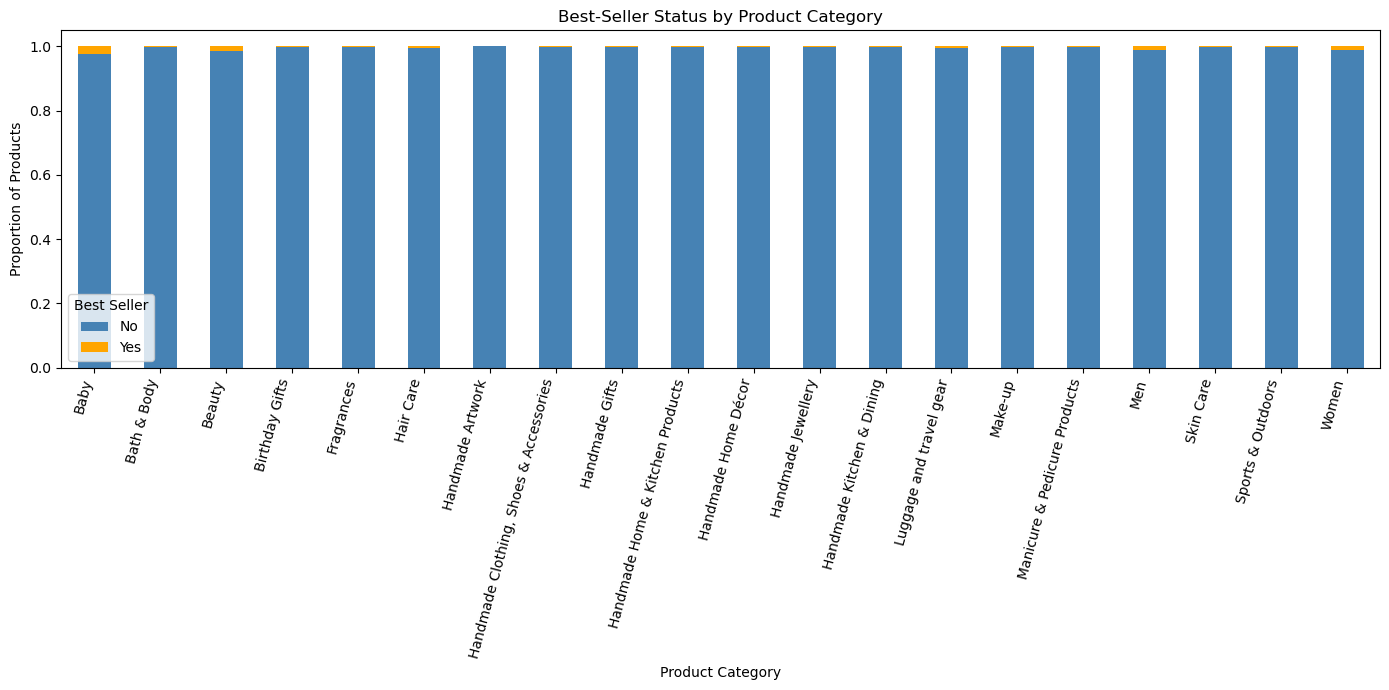

In [8]:
import matplotlib.pyplot as plt

# Select the 20 categories containing the most products
top_categories = data['category'].value_counts().head(20).index

# Create the crosstab and convert counts to row percentages
plot_data = pd.crosstab(
    data.loc[data['category'].isin(top_categories), 'category'],
    data.loc[data['category'].isin(top_categories), 'isBestSeller'],
    normalize='index'
)

# Plot
plot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=['steelblue', 'orange']
)

plt.title('Best-Seller Status by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Proportion of Products')
plt.legend(
    title='Best Seller',
    labels=['No', 'Yes']
)
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

PART II

2.1 Calculate the quartiles and IQR

In [9]:
Q1 = data['price'].quantile(0.25)
Q3 = data['price'].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 9.99
Q3: 45.99
IQR: 36.0


Q1 is the price below which 25% of products fall.
Q3 is the price below which 75% of products fall.
IQR is the range containing the middle 50% of prices.

Calculate the outlier boundaries

In [10]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

Lower boundary: -44.01
Upper boundary: 99.99000000000001


Create the filtered DataFrame

In [11]:
data_no_outliers = data[
    data['price'].between(lower_bound, upper_bound)
].copy()

Checking rows removed

In [12]:
print("Original number of products:", len(data))
print("Products after removing outliers:", len(data_no_outliers))
print("Outliers removed:", len(data) - len(data_no_outliers))

Original number of products: 2443651
Products after removing outliers: 2115963
Outliers removed: 327688


In [13]:
percentage_removed = (
    (len(data) - len(data_no_outliers)) / len(data) * 100
)

print(f"Percentage removed: {percentage_removed:.2f}%")

Percentage removed: 13.41%


In [14]:
price_outliers = data[
    (data['price'] < lower_bound) |
    (data['price'] > upper_bound)
]

price_outliers[
    ['title', 'category', 'price']
].sort_values('price', ascending=False).head(10)

,title,category,price
2008013,HB FBA Test Treadmill,Sports & Outdoors,100000.00
1987238,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,Desktop PCs,77752.00
1905315,Abaodam decor christmas ornaments Desk Ornamen...,Garden Storage & Housing,24674.59
1408966,BM4445-FI1-01200R10-03-E03 Driver,Scanners & Accessories,23482.73
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,Projectors,22933.42
1490286,YXHUI Kids Girls Figure Skating Dress Long Sle...,Sports & Outdoors,21999.00
1490285,YXHUI Kids Girls Figure Skating Dress Long Sle...,Sports & Outdoors,21999.00
1907271,Outdoor Furniture Wood Porch Swing Black Brown...,Garden Storage & Housing,21464.82
1907272,Outdoor Furniture Wood Porch Swing Black Brown...,Garden Storage & Housing,21464.82
1907273,Outdoor Furniture Wood Porch Swing Black Brown...,Garden Storage & Housing,21464.82


2.2 Violin Plots:

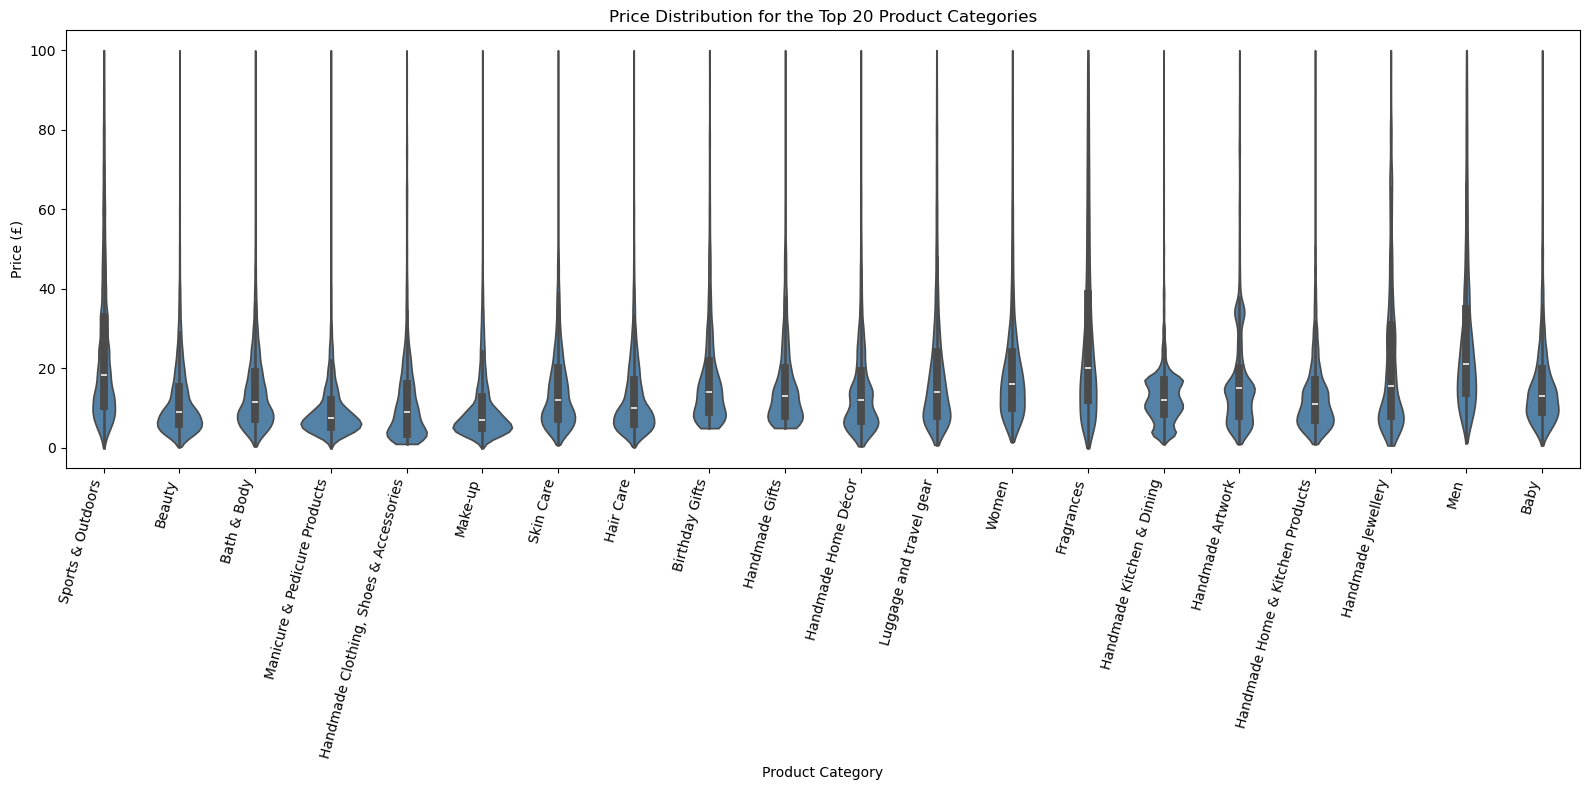

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Find the 20 categories with the most products
top_20_categories = (
    data_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

# Filter the data to those categories
data_top_20 = data_no_outliers[
    data_no_outliers['category'].isin(top_20_categories)
]

# Create the violin plot
plt.figure(figsize=(16, 8))

sns.violinplot(
    data=data_top_20,
    x='category',
    y='price',
    order=top_20_categories,
    color='steelblue',
    cut=0
)

plt.title('Price Distribution for the Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price (£)')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

The violin plot displays the price distributions of the 20 categories containing the most products after removing price outliers. The category with the highest median price was identified separately by grouping the complete filtered dataset by category and sorting the category median prices in descending order.

2.3 Average price for the top 10 categories

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Identify the 10 categories with the most products
top_10_categories = (
    data_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

# Filter to those categories
data_top_10 = data_no_outliers[
    data_no_outliers['category'].isin(top_10_categories)
]

# Calculate average price
top_10_average_prices = (
    data_top_10
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

top_10_average_prices

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

Bar chart

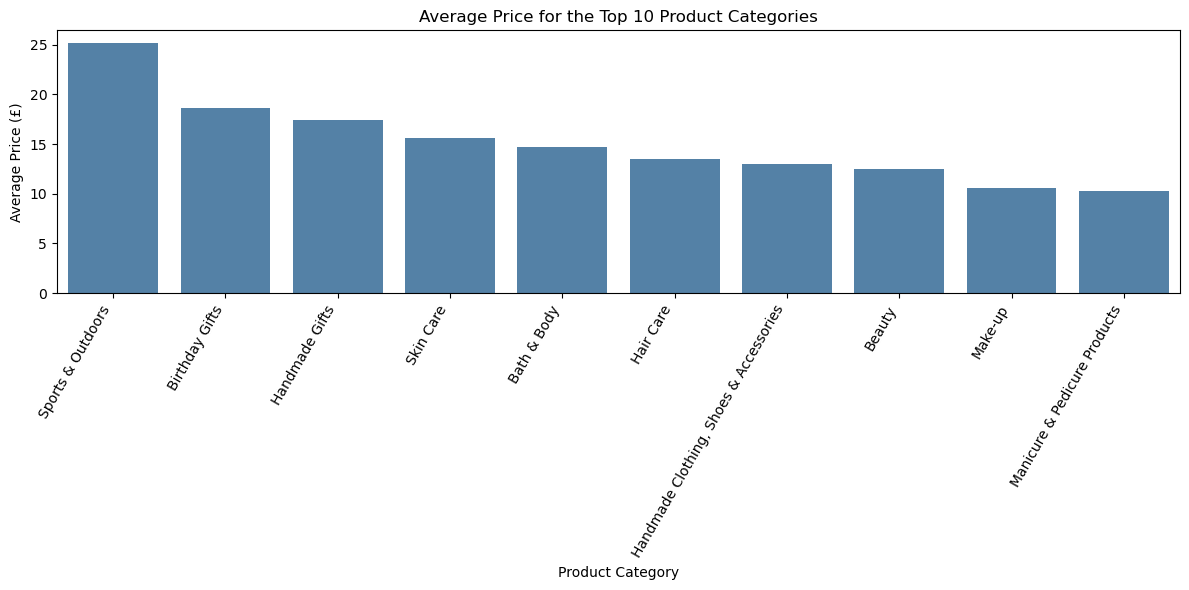

In [17]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_average_prices.index,
    y=top_10_average_prices.values,
    color='steelblue'
)

plt.title('Average Price for the Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price (£)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [18]:
average_price_all_categories = (
    data_no_outliers
    .groupby('category')['price']
    .agg(
        product_count='size',
        average_price='mean'
    )
    .sort_values('average_price', ascending=False)
)

average_price_all_categories.head(10)

,product_count,average_price
category,,
Motherboards,74,68.772432
Boxing Shoes,3873,67.417803
Desktop PCs,169,66.915562
Tablets,4638,66.552971
Graphics Cards,57,65.103509
Digital Frames,310,60.745129
Streaming Clients,1692,60.241803
Hockey Shoes,221,60.094796
Computer Cases,173,58.339884


2.4 Box Plots:

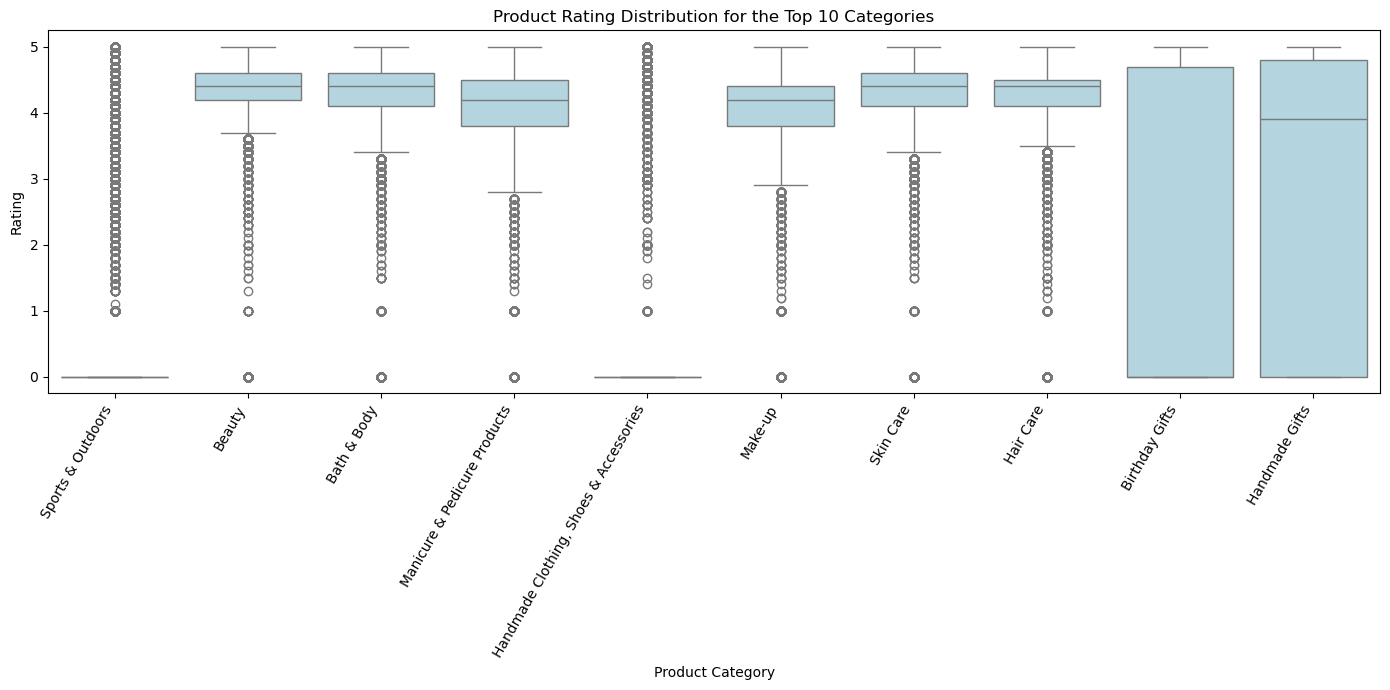

In [19]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=data_top_10,
    x='category',
    y='stars',
    order=top_10_categories,
    color='lightblue'
)

plt.title('Product Rating Distribution for the Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [20]:
median_rating_all_categories = (
    data_no_outliers
    .groupby('category')['stars']
    .agg(
        product_count='size',
        median_rating='median'
    )
    .sort_values('median_rating', ascending=False)
)

median_rating_all_categories.head(10)

,product_count,median_rating
category,,
Computer Memory,211,4.7
Building & Construction Toys,8685,4.6
Office Paper Products,9090,4.6
Luxury Food & Drink,657,4.6
Kids' Play Figures,9377,4.6
Hobbies,9065,4.6
"Beer, Wine & Spirits",9271,4.6
Laptop Accessories,250,4.6
Cables & Accessories,9031,4.5


In [21]:
highest_rating_category = median_rating_all_categories.index[0]
highest_median_rating = median_rating_all_categories.iloc[0]['median_rating']

print(
    f"The category with the highest median rating is "
    f"{highest_rating_category}, with a median rating of "
    f"{highest_median_rating:.1f} stars."
)

The category with the highest median rating is Computer Memory, with a median rating of 4.7 stars.


3. Correlation coefficient

In [22]:
correlation = data_no_outliers['price'].corr(
    data_no_outliers['stars']
)

print(f"Pearson correlation: {correlation:.3f}")

Pearson correlation: -0.078


In [23]:
from scipy.stats import pearsonr

correlation_data = (
    data_no_outliers[['price', 'stars']]
    .dropna()
)

r, p_value = pearsonr(
    correlation_data['price'],
    correlation_data['stars']
)

print(f"Pearson correlation: {r:.3f}")
print(f"P-value: {p_value:.6f}")

Pearson correlation: -0.078
P-value: 0.000000


In [24]:
if p_value < 0.05:
    print("The correlation is statistically significant.")
else:
    print("The correlation is not statistically significant.")

The correlation is statistically significant.


Scatter Plots

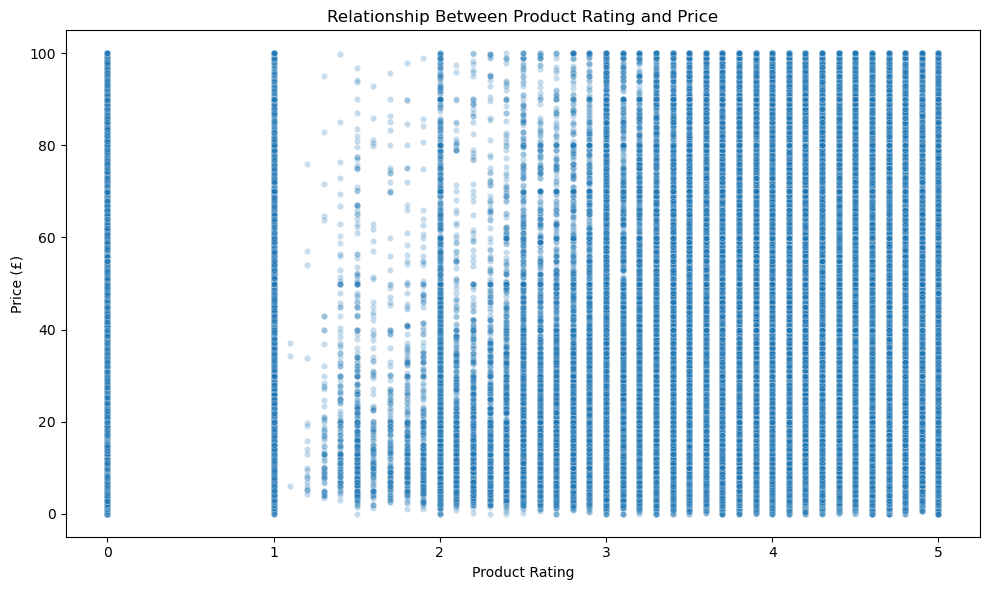

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data_no_outliers,
    x='stars',
    y='price',
    alpha=0.25,
    s=20
)

plt.title('Relationship Between Product Rating and Price')
plt.xlabel('Product Rating')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.show()

In [30]:
correlation_sample = correlation_data.sample(
    n=10000,
    random_state=42
)

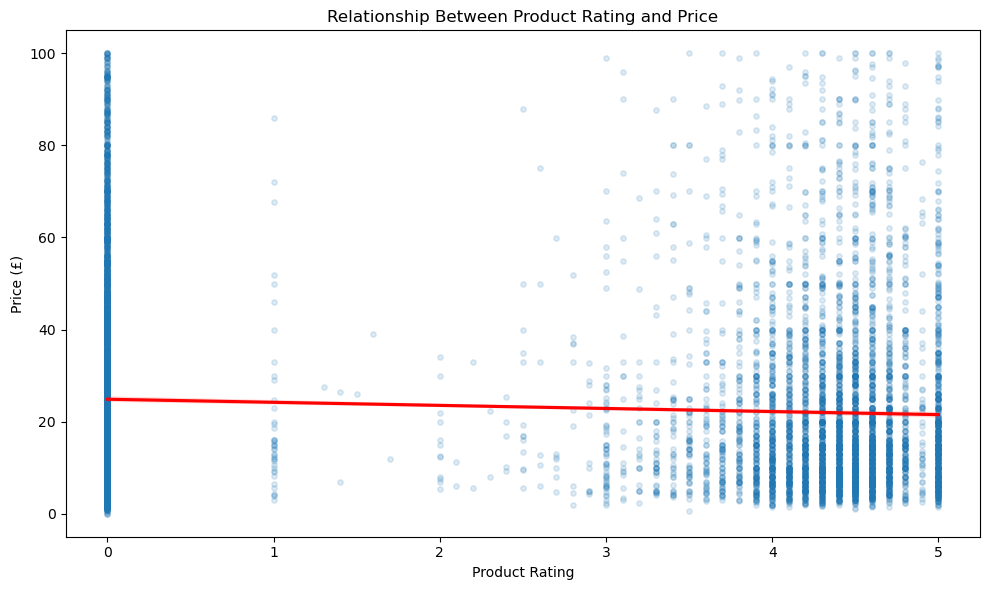

In [35]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=correlation_sample,
    x='stars',
    y='price',
    scatter_kws={'alpha': 0.15, 's': 15},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Product Rating and Price')
plt.xlabel('Product Rating')
plt.ylabel('Price (£)')
plt.tight_layout()
plt.show()

We observe a small decreasing relationship between product rating and price

In [36]:
numerical_columns = [
    'stars',
    'reviews',
    'price',
    'boughtInLastMonth'
]

correlation_matrix = (
    data_no_outliers[numerical_columns]
    .corr()
)

correlation_matrix

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.083920,-0.077673,0.113994
reviews,0.083920,1.000000,-0.008498,0.105624
price,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.113994,0.105624,-0.059051,1.000000


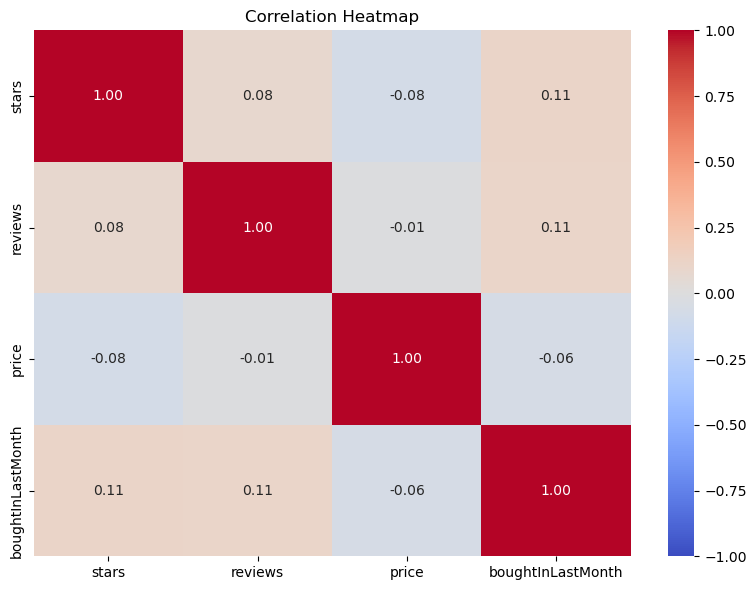

In [37]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

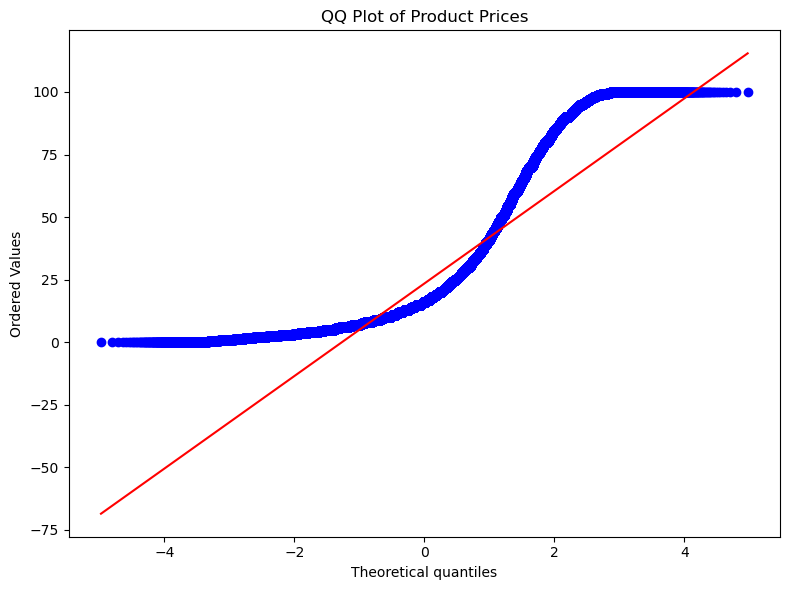

In [38]:
from scipy import stats

plt.figure(figsize=(8, 6))

stats.probplot(
    data_no_outliers['price'].dropna(),
    dist='norm',
    plot=plt
)

plt.title('QQ Plot of Product Prices')
plt.tight_layout()
plt.show()